In [15]:
import numpy as np
import matplotlib.pyplot as plt

In [23]:
class Detector:
    def __init__(self, R, N, r, a):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        
        self.pmt_coords = self._generate_pmt_coordinates()

    def _generate_pmt_coordinates(self):
        #генерация с исользованием спирали Фиббоначи
        points = []
        phi = np.pi * (3. - np.sqrt(5.)) 
        
        for i in range(self.N):
            y = 1 - (i / float(self.N - 1)) * 2
            radius = np.sqrt(1 - y * y)
            theta = phi * i
            
            x = np.cos(theta) * radius
            z = np.sin(theta) * radius
            
            points.append([x * self.R, y * self.R, z * self.R])
            
        return np.array(points)

    def is_point_in_pmt(self, point):
        point = np.array(point)
        
        if not np.isclose(np.linalg.norm(point), self.R, rtol=1e-3):
            return False, None 
            
        distances = np.linalg.norm(self.pmt_coords - point, axis=1)
        
        min_dist = np.min(distances)
        closest_pmt_idx = np.argmin(distances)
        
        if min_dist <= self.r:
            return True, closest_pmt_idx
        else:
            return False, None
    def find_intersection(self, origin, directions):
        p = np.array(origin)
        # Векторизованное решение квадратного уравнения: |p + t*n|^2 = R^2
        # t^2 + 2(p*n)t + (p^2 - R^2) = 0
        b = np.dot(directions, p)
        c = np.dot(p, p) - self.R**2
        
        discriminant = b**2 - c
        #рассматриваем только положительный корень (отрицательный физически означает движение назад и нам не подходит)
        t = -b + np.sqrt(discriminant)
        
        # Координаты пересечения
        intersections = p + t[:, np.newaxis] * directions
        return intersections

    def generate_photoelectrons(self, num_hits_per_pmt):
        means = self.a * num_hits_per_pmt
        return np.random.poisson(means)
    def get_hits_per_pmt(detector, intersections):
        hits = np.zeros(detector.N, dtype=int)
        dists = np.linalg.norm(intersections[:, np.newaxis, :] - detector.pmt_coords[np.newaxis, :, :], axis=2)
        closest_pmt_idx = np.argmin(dists, axis=1)
        min_dists = np.min(dists, axis=1)
        # Отбираем те фотоны, которые попали в радиус ФЭУ (r)
        valid_hits = min_dists <= detector.r
        hit_indices = closest_pmt_idx[valid_hits]
        hits = np.bincount(hit_indices, minlength=detector.N)
    
        return hits


In [18]:
class Source:
    def __init__(self, Y=10000):
        self.Y = Y

    def generate_photons(self, E):
        N_photons = int(self.Y * E)
        if N_photons <= 0:
            return np.empty((0, 3))
        vectors = np.random.normal(loc=0.0, scale=1.0, size=(N_photons, 3))
        norms = np.linalg.norm(vectors, axis=1, keepdims=True)
        directions = vectors / norms
        
        return directions

In [24]:
def simulate_events(detector, source, origin, energy, num_events):
    charges = []
    for _ in range(num_events):
        dirs = source.generate_photons(energy)
        if len(dirs) == 0:
            charges.append(0)
            continue
        intersections = detector.find_intersection(origin, dirs)
        hits = detector.get_hits_per_pmt(intersections)
        pe = detector.generate_photoelectrons(hits)
        charges.append(np.sum(pe))
    return np.array(charges)

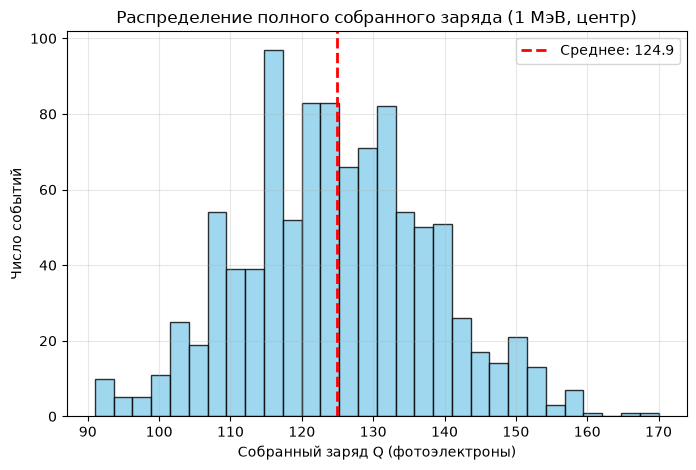

Среднее значение: 124.93
Стандартное отклонение: 13.16
Относительная ширина (σ/μ): 0.1054


In [26]:
det = Detector(R=2.0, N=40, r=0.1, a=0.5)
src = Source(Y=10000)
origin_center = (0.0, 0.0, 0.0)
E = 1.0 # МэВ
N_events = 1000

# Запуск симуляции
charges_1MeV = simulate_events(det, src, origin_center, E, N_events)

# Построение гистограммы
plt.figure(figsize=(8, 5))
plt.hist(charges_1MeV, bins=30, color='skyblue', edgecolor='black', alpha=0.8)
plt.axvline(np.mean(charges_1MeV), color='red', linestyle='dashed', linewidth=2, label=f'Среднее: {np.mean(charges_1MeV):.1f}')
plt.title('Распределение полного собранного заряда (1 МэВ, центр)')
plt.xlabel('Собранный заряд Q (фотоэлектроны)')
plt.ylabel('Число событий')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Среднее значение: {np.mean(charges_1MeV):.2f}")
print(f"Стандартное отклонение: {np.std(charges_1MeV):.2f}")
print(f"Относительная ширина (σ/μ): {np.std(charges_1MeV)/np.mean(charges_1MeV):.4f}")

Энергия | Среднее | Ст.отклонение | Отн. ширина
--------------------------------------------------
0.2 МэВ |   24.90 |         6.10 | 0.2448
0.5 МэВ |   62.74 |         9.71 | 0.1548
0.7 МэВ |   87.16 |        11.62 | 0.1333
1.0 МэВ |  124.87 |        13.67 | 0.1095
1.5 МэВ |  187.79 |        16.95 | 0.0903
2.0 МэВ |  249.66 |        19.29 | 0.0773
3.0 МэВ |  375.41 |        23.81 | 0.0634


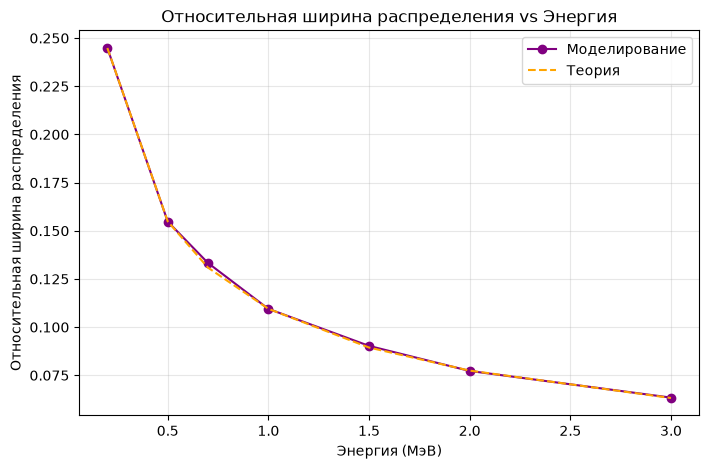

In [28]:
energies = [0.2, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0]
events_per_E = 1000 

means = []
stds = []
rel_widths = []

print("Энергия | Среднее | Ст.отклонение | Отн. ширина")
print("-" * 50)

for E in energies:
    ch = simulate_events(det, src, origin_center, E, events_per_E)
    mu = np.mean(ch)
    sigma = np.std(ch)
    rel_width = sigma / mu
    
    means.append(mu)
    stds.append(sigma)
    rel_widths.append(rel_width)
    
    print(f"{E:.1f} МэВ | {mu:7.2f} | {sigma:12.2f} | {rel_width:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(energies, rel_widths, 'o-', color='purple', label='Моделирование')
C = rel_widths[0] * np.sqrt(energies[0]) # Константа из первой точки
plt.plot(energies, C / np.sqrt(energies), '--', color='orange', label=r'Теория')

plt.title('Относительная ширина распределения vs Энергия')
plt.xlabel('Энергия (МэВ)')
plt.ylabel(r'Относительная ширина распределения')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Средний заряд (в центре): 124.93
Средний заряд (смещен на 1м): 123.79
Разница: -1.14 (-0.91%)


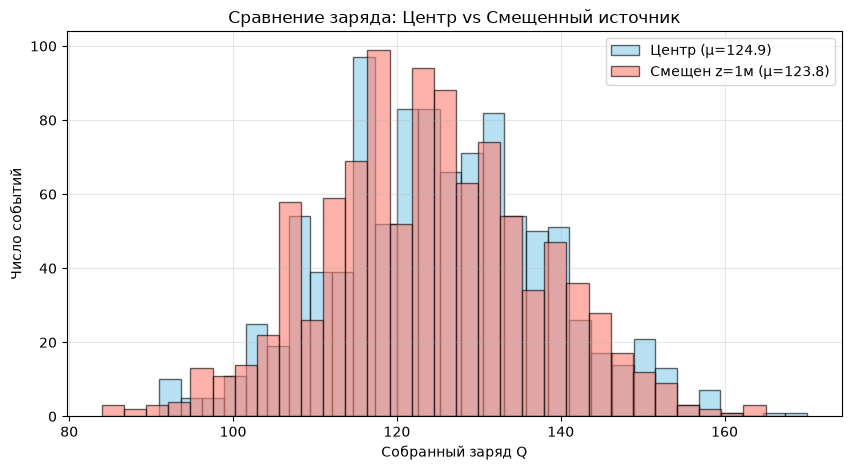

In [30]:
origin_shifted = (0.0, 0.0, 1.0) # Смещение на 1 м по оси z
E = 1.0
N_events = 1000

charges_shifted = simulate_events(det, src, origin_shifted, E, N_events)

mean_center = np.mean(charges_1MeV)
mean_shifted = np.mean(charges_shifted)

print(f"Средний заряд (в центре): {mean_center:.2f}")
print(f"Средний заряд (смещен на 1м): {mean_shifted:.2f}")
print(f"Разница: {mean_shifted - mean_center:.2f} ({(mean_shifted - mean_center)/mean_center * 100:.2f}%)")

plt.figure(figsize=(10, 5))
plt.hist(charges_1MeV, bins=30, color='skyblue', edgecolor='black', alpha=0.6, label=f'Центр (μ={mean_center:.1f})')
plt.hist(charges_shifted, bins=30, color='salmon', edgecolor='black', alpha=0.6, label=f'Смещен z=1м (μ={mean_shifted:.1f})')
plt.title('Сравнение заряда: Центр vs Смещенный источник')
plt.xlabel('Собранный заряд Q')
plt.ylabel('Число событий')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()